In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
import os
from scipy.interpolate import InterpolatedUnivariateSpline as inspl

## Notepad para graficación básica de datos (pstability)

In [17]:
# Leyendo archivos de datos (sim)
zheng = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\zheng')
hu = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\hu')
zhang = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\zhang')
wu = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\wu')
schmidt = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\schmidt')

# Archivos de datos para la plot general
zheng2 = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\zheng2')
hu2 = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\hu2')
zhang2 = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\zhang2')
wu2 = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\wu2')
schmidt2 = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\sim\schmidt2')

In [18]:
# Leyendo archivos de datos (exp)
chapman = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\exp\chapman')
im = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\exp\Im')
vervoorts = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\pstability\exp\vervoorts')

In [19]:
# Transformando
zheng = np.transpose(zheng)
hu = np.transpose(hu)
zhang = np.transpose(zhang)
wu = np.transpose(wu)
schmidt = np.transpose(schmidt)

zheng2 = np.transpose(zheng2)
hu2 = np.transpose(hu2)
zhang2 = np.transpose(zhang2)
wu2 = np.transpose(wu2)
schmidt2 = np.transpose(schmidt2)

chapman = np.transpose(chapman)
im = np.transpose(im)
vervoorts = np.transpose(vervoorts)

zheng

array([[0.00000e+00, 1.00000e+03, 2.00000e+03, 3.00000e+03, 4.00000e+03,
        5.00000e+03, 6.00000e+03, 7.00000e+03, 8.00000e+03, 9.00000e+03,
        1.00000e+04, 1.20000e+04, 1.40000e+04, 1.60000e+04],
       [3.35666e+01, 3.34402e+01, 3.33117e+01, 3.31897e+01, 3.30739e+01,
        3.29545e+01, 3.28442e+01, 3.27340e+01, 3.26283e+01, 3.25251e+01,
        3.24242e+01, 3.22353e+01, 3.20526e+01, 3.18801e+01],
       [3.35699e+01, 3.34400e+01, 3.33111e+01, 3.31912e+01, 3.30709e+01,
        3.29551e+01, 3.28424e+01, 3.27295e+01, 3.26268e+01, 3.25228e+01,
        3.24238e+01, 3.22365e+01, 3.20563e+01, 3.18806e+01],
       [3.35717e+01, 3.34389e+01, 3.33126e+01, 3.31913e+01, 3.30707e+01,
        3.29548e+01, 3.28414e+01, 3.27324e+01, 3.26286e+01, 3.25251e+01,
        3.24239e+01, 3.22340e+01, 3.20508e+01, 3.18788e+01],
       [3.78292e+04, 3.73923e+04, 3.69649e+04, 3.65634e+04, 3.61717e+04,
        3.57891e+04, 3.54251e+04, 3.50680e+04, 3.47345e+04, 3.44047e+04,
        3.40872e+04, 3.349

In [20]:
# Volume to Lparam
zheng[4] = [0.5*((x)**(1/3)) for x in zheng[4]]
hu[4] = [0.5*((x)**(1/3)) for x in hu[4]]
zhang[4] = [0.5*((x)**(1/3)) for x in zhang[4]]
wu[4] = [0.5*((x)**(1/3)) for x in wu[4]]
schmidt[4] = [0.5*((x)**(1/3)) for x in schmidt[4]]

zheng2[4] = [0.5*((x)**(1/3)) for x in zheng2[4]]
hu2[4] = [0.5*((x)**(1/3)) for x in hu2[4]]
zhang2[4] = [0.5*((x)**(1/3)) for x in zhang2[4]]
wu2[4] = [0.5*((x)**(1/3)) for x in wu2[4]]
schmidt2[4] = [0.5*((x)**(1/3)) for x in schmidt2[4]]

#zheng[4]

In [21]:
# atm to GPa
zheng[0] = [(1.0 / 9869.23266716) * x for x in zheng[0]]
hu[0] = [(1.0 / 9869.23266716) * x for x in hu[0]]
zhang[0] = [(1.0 / 9869.23266716) * x for x in zhang[0]]
wu[0] = [(1.0 / 9869.23266716) * x for x in wu[0]]
schmidt[0] = [(1.0 / 9869.23266716) * x for x in schmidt[0]]

zheng2[0] = [(1.0 / 9869.23266716) * x for x in zheng2[0]]
hu2[0] = [(1.0 / 9869.23266716) * x for x in hu2[0]]
zhang2[0] = [(1.0 / 9869.23266716) * x for x in zhang2[0]]
wu2[0] = [(1.0 / 9869.23266716) * x for x in wu2[0]]
schmidt2[0] = [(1.0 / 9869.23266716) * x for x in schmidt2[0]]
#zheng[0]

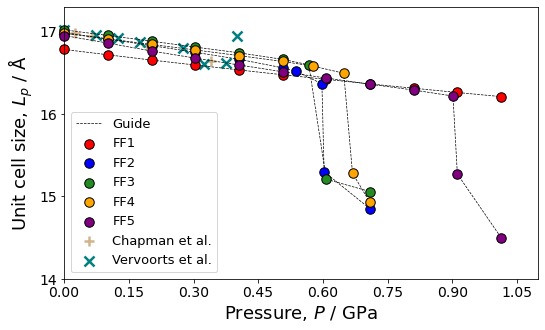

In [22]:
#Plotting

fig = plt.figure()
fig.set_size_inches(8.5, 5.0, forward=True) # 5 by 5 for individual plots. 8.5 by 5 for the one that includes all.
plt.xlabel(r"Pressure, $P$ / $\mathrm{GPa}$", fontsize=18)
plt.ylabel(r"Unit cell size, $L_{p}$ / $\mathrm{\AA}$", fontsize=18)

# Plot Zheng2012
#plt.axis([0.0, 1.45, 15.5, 17.3])
#plt.xticks(np.arange(0.0, 1.45, 0.35), fontsize=14)
#plt.yticks(np.arange(15.5, 17.3, 0.5), fontsize=14)
#plt.scatter(zheng[0], zheng[4], marker='o', color='red', edgecolor='black', linewidth=1.5, s=110, zorder=2, label='FF1 simulated', clip_on=False)
#plt.plot(zheng[0], zheng[4], linestyle='--', color='black', label='Guide', zorder=1)

# Plot Hu2012
#plt.axis([0.0, 0.85, 14.0, 17.3])
#plt.xticks(np.arange(0.0, 0.85, 0.2), fontsize=14)
#plt.yticks(np.arange(14.0, 17.3, 1.0), fontsize=14)
#plt.scatter(hu[0], hu[4], marker='o', color='red', edgecolor='black', linewidth=1.5, s=110, zorder=2, label='FF2 simulated', clip_on=False)
#plt.plot(hu[0], hu[4], linestyle='--', color='black', label='Guide', zorder=1)

# Plot Zhang2013
#plt.scatter(zhang[0], zhang[4], marker='o', color='red', edgecolor='black', linewidth=1.5, s=110, zorder=2, label='FF3 simulated', clip_on=False)
#plt.plot(zhang[0], zhang[4], linestyle='--', color='black', label='Guide', zorder=1)
#plt.axis([0.0, 0.95, 14.0, 17.3])
#plt.xticks(np.arange(0.0, 0.95, 0.2), fontsize=14)
#plt.yticks(np.arange(14.0, 17.3, 1.0), fontsize=14)

# Plot Wu2014
#plt.scatter(wu[0], wu[4], marker='o', color='red', edgecolor='black', linewidth=1.5, s=110, zorder=2, label='FF4 simulated', clip_on=False)
#plt.plot(wu[0], wu[4], linestyle='--', color='black', label='Guide', zorder=1)
#plt.axis([0.0, 0.85, 14.0, 17.3])
#plt.xticks(np.arange(0.0, 0.85, 0.2), fontsize=14)
#plt.yticks(np.arange(14.0, 17.3, 1.0), fontsize=14)

# Plot Schmidt 2019
#plt.scatter(schmidt[0], schmidt[4], marker='o', color='red', edgecolor='black', linewidth=1.5, s=110, zorder=2, label='FF5 simulated', clip_on=False)
#plt.plot(schmidt[0], schmidt[4], linestyle='--', color='black', label='Guide', zorder=1)
#plt.axis([0.0, 1.05, 14.0, 17.3])
#plt.xticks(np.arange(0.0, 1.05, 0.25), fontsize=14)
#plt.yticks(np.arange(14.0, 17.3, 1.0), fontsize=14)

# Plot ALL
plt.axis([0.0, 1.10, 14, 17.3])
plt.xticks(np.arange(0.0, 1.10, 0.15), fontsize=14)
plt.yticks(np.arange(14, 17.3, 1.0), fontsize=14)
plt.scatter(zheng2[0], zheng2[4], marker='o', color='red', edgecolor='black', linewidth=1.0, s=90, zorder=2, label='FF1', clip_on=False)
plt.plot(zheng2[0], zheng2[4], linestyle='--', color='black', label='Guide', zorder=1, linewidth=.7)
plt.scatter(hu2[0], hu2[4], marker='o', color='blue', edgecolor='black', linewidth=1.0, s=90, zorder=2, label='FF2', clip_on=False)
plt.plot(hu2[0], hu2[4], linestyle='--', color='black', zorder=1, linewidth=.7)
plt.scatter(zhang2[0], zhang2[4], marker='o', color='forestgreen', edgecolor='black', linewidth=1.0, s=90, zorder=2, label='FF3', clip_on=False)
plt.plot(zhang2[0], zhang2[4], linestyle='--', color='black', zorder=1, linewidth=.7)
plt.scatter(wu2[0], wu2[4], marker='o', color='orange', edgecolor='black', linewidth=1.0, s=90, zorder=2, label='FF4', clip_on=False)
plt.plot(wu2[0], wu2[4], linestyle='--', color='black', zorder=1, linewidth=.7)
plt.scatter(schmidt2[0], schmidt2[4], marker='o', color='purple', edgecolor='black', linewidth=1.0, s=90, zorder=2, label='FF5', clip_on=False)
plt.plot(schmidt2[0], schmidt2[4], linestyle='--', color='black', zorder=1, linewidth=.7)


    
#Experimental data
#plt.scatter(im[0], im[1], marker='x', color='brown', linewidth=2, s=110, label='Im et al.', zorder=1, clip_on=False)
plt.scatter(chapman[0], chapman[1], marker='+', color='tan', linewidth=2.5, s=100, label='Chapman et al.', zorder=1, clip_on=False)
plt.scatter(vervoorts[0], vervoorts[1], marker='x', color='teal', linewidth=2.5, s=100, label='Vervoorts et al.', zorder=1, clip_on=False)


plt.legend(facecolor='white', fontsize=13, framealpha=0.8)
#plt.grid(True, linestyle='--')
fig.savefig(r'C:\Users\20210015\Documents\ZIF8manu16June\images\pstab\all_pstability.png', bbox_inches='tight', dpi=500)
fig.savefig(r'C:\Users\20210015\Documents\ZIF8manu16June\images\pstab\all_pstability.pdf', bbox_inches='tight')

plt.show()